# Codificación de las etiquetas en clasificación

In [1]:
from sklearn.preprocessing import OneHotEncoder, LabelEncoder
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [2]:
#LEEMOS LOS DATOS DEL IRIS DATASET
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/iris/iris.data"

# El conjunto de datos Iris no tiene encabezado, agregaremos nombres a las columnas en español
nombres_columnas = ['longitud_sepalo', 'ancho_sepalo', 'longitud_petalo', 'ancho_petalo', 'clase']

# Leer desde la URL con pandas
data = pd.read_csv(url, names=nombres_columnas)

In [4]:
# Pasamos las etiquetas a numpy y visualizamos
y = data.clase.to_numpy()
y

array(['Iris-setosa', 'Iris-setosa', 'Iris-setosa', 'Iris-setosa',
       'Iris-setosa', 'Iris-setosa', 'Iris-setosa', 'Iris-setosa',
       'Iris-setosa', 'Iris-setosa', 'Iris-setosa', 'Iris-setosa',
       'Iris-setosa', 'Iris-setosa', 'Iris-setosa', 'Iris-setosa',
       'Iris-setosa', 'Iris-setosa', 'Iris-setosa', 'Iris-setosa',
       'Iris-setosa', 'Iris-setosa', 'Iris-setosa', 'Iris-setosa',
       'Iris-setosa', 'Iris-setosa', 'Iris-setosa', 'Iris-setosa',
       'Iris-setosa', 'Iris-setosa', 'Iris-setosa', 'Iris-setosa',
       'Iris-setosa', 'Iris-setosa', 'Iris-setosa', 'Iris-setosa',
       'Iris-setosa', 'Iris-setosa', 'Iris-setosa', 'Iris-setosa',
       'Iris-setosa', 'Iris-setosa', 'Iris-setosa', 'Iris-setosa',
       'Iris-setosa', 'Iris-setosa', 'Iris-setosa', 'Iris-setosa',
       'Iris-setosa', 'Iris-setosa', 'Iris-versicolor', 'Iris-versicolor',
       'Iris-versicolor', 'Iris-versicolor', 'Iris-versicolor',
       'Iris-versicolor', 'Iris-versicolor', 'Iris-versic

In [5]:
# Codificación con Label Encoding (y={0,1,...})
label_encoder = LabelEncoder()
y_labels = label_encoder.fit_transform(y)

#visualizamos
y_labels

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2])

In [6]:
# Codificación con One-Hot Encoding usando `sparse_output`
onehot_encoder = OneHotEncoder(sparse_output=False)
y_onehot = onehot_encoder.fit_transform(y.reshape(-1, 1))
y_onehot[0:10]

array([[1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.]])

In [7]:
# Vemos las dimensiones del array y_onehot:
y_onehot.shape

(150, 3)

In [8]:
# Convertimos los resultados a DataFrame para una mejor visualización
df_onehot = pd.DataFrame(y_onehot, columns=['Class 0', 'Class 1', 'Class 2'])
df_onehot

,Class 0,Class 1,Class 2
0,1.0,0.0,0.0
1,1.0,0.0,0.0
2,1.0,0.0,0.0
3,1.0,0.0,0.0
4,1.0,0.0,0.0
...,...,...,...
145,0.0,0.0,1.0
146,0.0,0.0,1.0
147,0.0,0.0,1.0
148,0.0,0.0,1.0


In [9]:
# Convertimos los resultados de la otra codificación a DataFrame para una mejor visualización
df_labels = pd.DataFrame(y_labels, columns=['Label'])
df_labels

,Label
0,0
1,0
2,0
3,0
4,0
...,...
145,2
146,2
147,2
148,2


# CLASIFICACIÓN BINARIA EN UNA DIMENSIÓN

In [10]:
# En este caso vamos a leer los datos con la biblioteca sklearn
from sklearn.datasets import load_iris

# Carganos el conjunto de datos Iris con la biblioteca sklearn y seleccionamos solo las dos primeras clases para la clasificación binaria
iris = load_iris()
X = iris.data[iris.target != 2, 0:1]  # Usamos solo la primera característica y las dos primeras clases (0 y 1)
y = iris.target[iris.target != 2] # eliminamos la clase 2 en la variable objetivo

X.shape

(100, 1)

In [11]:
#Tamaño de y
y.shape

(100,)

In [12]:
#visualizamos la codificación de y
y

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1])

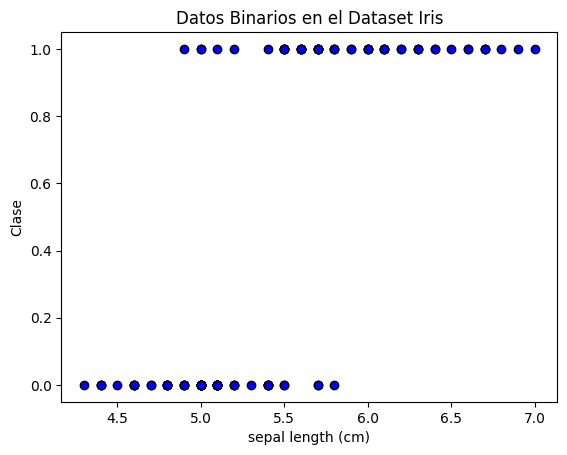

In [13]:
# Representamos los datos
plt.scatter(X, y, color='blue', edgecolor='k')
plt.xlabel(iris.feature_names[0])
plt.ylabel('Clase')
plt.title('Datos Binarios en el Dataset Iris')
plt.show()

In [15]:
#CARGAMOS LA LIBRERÍA PARA REGRESIÓN LOGÍSTICA
from sklearn.linear_model import LogisticRegression

Más información sobre el algoritmo de Regresión Logística: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html

In [16]:
# Entrenamos un modelo de regresión logística
model = LogisticRegression()
model.fit(X, y)

# Coeficientes de la solución
coef = model.coef_[0]
intercept = model.intercept_

# Imprimimos los coeficientes del modelo
print('Término independiente: beta_0:', intercept)
print('Coeficiente: beta_1:', coef)

Término independiente: beta_0: [-17.24560256]
Coeficiente: beta_1: [3.17578826]


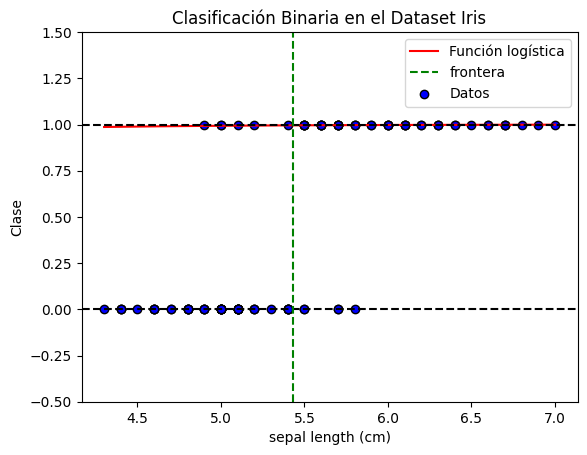

In [17]:
#REPRESENTAMOS LA FUNCIÓN LOGÍSTICA Y LA EC. DE FRONTERA

# Función logística (Para la exponencial usar np.exp)
def logistic_function(x):
    return 1 / (1 + np.exp(-x))

#Establecemos el dominio de x entre el máximo y el mínimo, utilizando mil puntos
x_values_logistic = np.linspace(np.min(X), np.max(X), 1000)
y_values_logistic = logistic_function(x_values_logistic)

plt.plot(x_values_logistic, y_values_logistic, color='red', label='Función logística')
plt.xlabel('x')
plt.ylabel('y')
plt.ylim(-0.5, 1.5)

# Representamos los ejes y = 0 y y = 1
plt.axhline(y=0, color='black', linestyle='--')
plt.axhline(y=1, color='black', linestyle='--')

# Calculamos y marcar el punto donde la función logística vale 0.5 (Ecuación de frontera)
x_05 = -intercept / coef

#Representamos una línea vertical en la frontera
plt.axvline(x=x_05, color='green', linestyle='--', label='frontera')

#Volvemos a representar los datos:
plt.scatter(X, y, color='blue', edgecolor='k', label='Datos')
plt.xlabel(iris.feature_names[0])
plt.ylabel('Clase')
plt.title('Clasificación Binaria en el Dataset Iris')
plt.legend()

plt.show()



# CLASIFICACIÓN BINARIA CON DOS DIMENSIONES

In [18]:
# Cargamos el conjunto de datos Iris
iris = load_iris()
X = iris.data[:, :2]  # Tomamos solo las primeras dos características
y = iris.target

# Creamos un filtro para quedarnos solo con dos clases (clasificación binaria)
filter = (y == 0) | (y == 1)
X = X[filter]
y = y[filter]

In [19]:
#Imprimimos la dimensión de X
X.shape

(100, 2)

In [20]:
#Imprimimos la dimensión de y
y.shape

(100,)

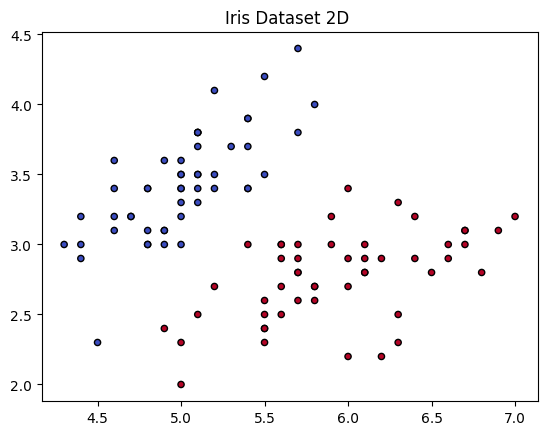

In [21]:
# Representamos los datos
plt.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm', edgecolor='k', s=20)
plt.title('Iris Dataset 2D ')

plt.show()

In [22]:
# Entrenamos un modelo de regresión logística
model = LogisticRegression()
model.fit(X, y)

# Coeficientes para la frontera de decisión
coef = model.coef_[0]
intercept = model.intercept_

# Imprimimos los coeficientes del modelo
print('Término independiente: beta_0:', intercept)
print('Coeficientes: beta_1, beta_2:', coef)

Término independiente: beta_0: [-7.33819169]
Coeficientes: beta_1, beta_2: [ 3.08267284 -3.01867739]


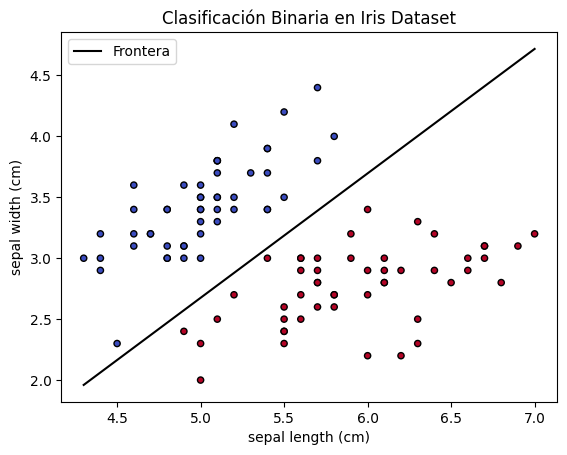

In [23]:
# REPRESENTAMOS LA ECUACIÓN DE FRONTERA JUNTO A LOS DATOS

# Sacamos los valores máximos y mínimos de la primera coordenada
# para determinar los extremos de la representación gráfica
x_values = np.array([np.min(X[:, 0]), np.max(X[:, 0])])

#Representamos la frontera de decisión
y_values = -(coef[0]/coef[1]) * x_values - intercept/coef[1]
plt.plot(x_values, y_values, color='black', label='Frontera')

# Representamos los datos de nuevo
plt.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm', edgecolor='k', s=20)

plt.xlabel(iris.feature_names[0])
plt.ylabel(iris.feature_names[1])
plt.title('Clasificación Binaria en Iris Dataset')
plt.legend()

plt.show()

# CLASIFICACIÓN CON TRES CLASES EN DOS DIMENSIONES

In [24]:
# Cargar el conjunto de datos Iris
iris = load_iris()
X = iris.data[:, :2]  # Tomamos solo las primeras dos características
y = iris.target

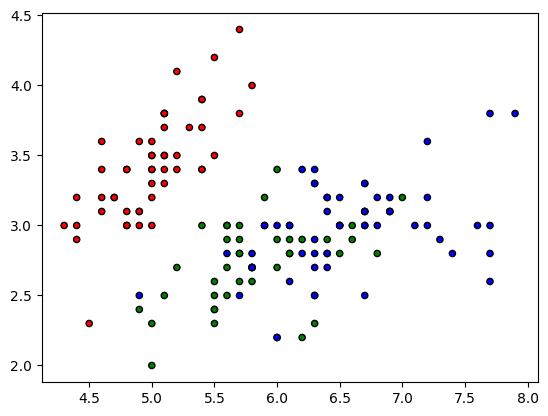

In [25]:
# Representamos  los datos
from matplotlib.colors import ListedColormap

#Colores para los datos
cmap_bold = ListedColormap(['red', 'green', 'blue'])

# Gráfico de dispersión
plt.scatter(X[:, 0], X[:, 1], c=y, cmap=cmap_bold, edgecolor='k', s=20)

plt.show()

In [26]:
# Creamos el modelo de clasificación KNN
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors=5)

# Entrenamos el modelo
knn.fit(X, y)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.Doesn't affect :meth:`fit` method.",None


In [27]:
# Creamos una malla de puntos para trazar la frontera de decisión
# Primero establecemos los límites
x_min = X[:, 0].min() - 1
x_max = X[:, 0].max() + 1

y_min = X[:, 1].min() - 1
y_max = X[:, 1].max() + 1

# Creamos una malla de puntos bidimensional entre los límites con espaciado 0.1
# entre los puntos
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 100),
                     np.linspace(y_min, y_max, 100))

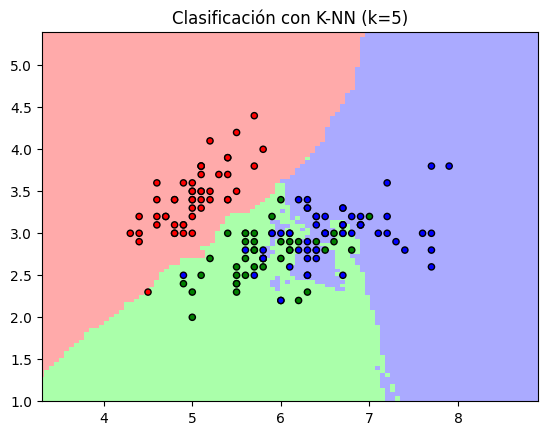

In [28]:
# Predecimos la clase para cada punto en la malla con el modelo entrenado
Z = knn.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# Colores para la gráfica
cmap_bold = ListedColormap(['red', 'green', 'blue'])
cmap_light = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF'])

# Representar la frontera de decisión
plt.figure()
plt.pcolormesh(xx, yy, Z, cmap=cmap_light)

# Representar también los datos de nuevo
plt.scatter(X[:, 0], X[:, 1], c=y, cmap=cmap_bold, edgecolor='k', s=20)

#Límites de la gráfica
plt.xlim(xx.min(), xx.max())
plt.ylim(yy.min(), yy.max())
plt.title("Clasificación con K-NN (k=5)")

plt.show()